# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Kadek Nathania Gavrila Astika | 5054251050 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [38]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_style('whitegrid')
RANDOM_STATE = 42

In [39]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')
print('Shape:', df.shape)
print()
df.info()
display(df.describe().T)

print('Missing value per kolom:')
print(df.isna().sum())
print('\nJumlah baris duplikat (semua kolom):', df.duplicated().sum())
print('Jumlah baris duplikat (tanpa status_id):', df.drop(columns='status_id').duplicated().sum())
print('\nKolom yang seluruhnya kosong:', df.columns[df.isna().all()].tolist())

Shape: (7050, 16)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   object 
 2   status_published  7050 non-null   object 
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10

,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


Missing value per kolom:
status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

Jumlah baris duplikat (semua kolom): 0
Jumlah baris duplikat (tanpa status_id): 54

Kolom yang seluruhnya kosong: ['Column1', 'Column2', 'Column3', 'Column4']


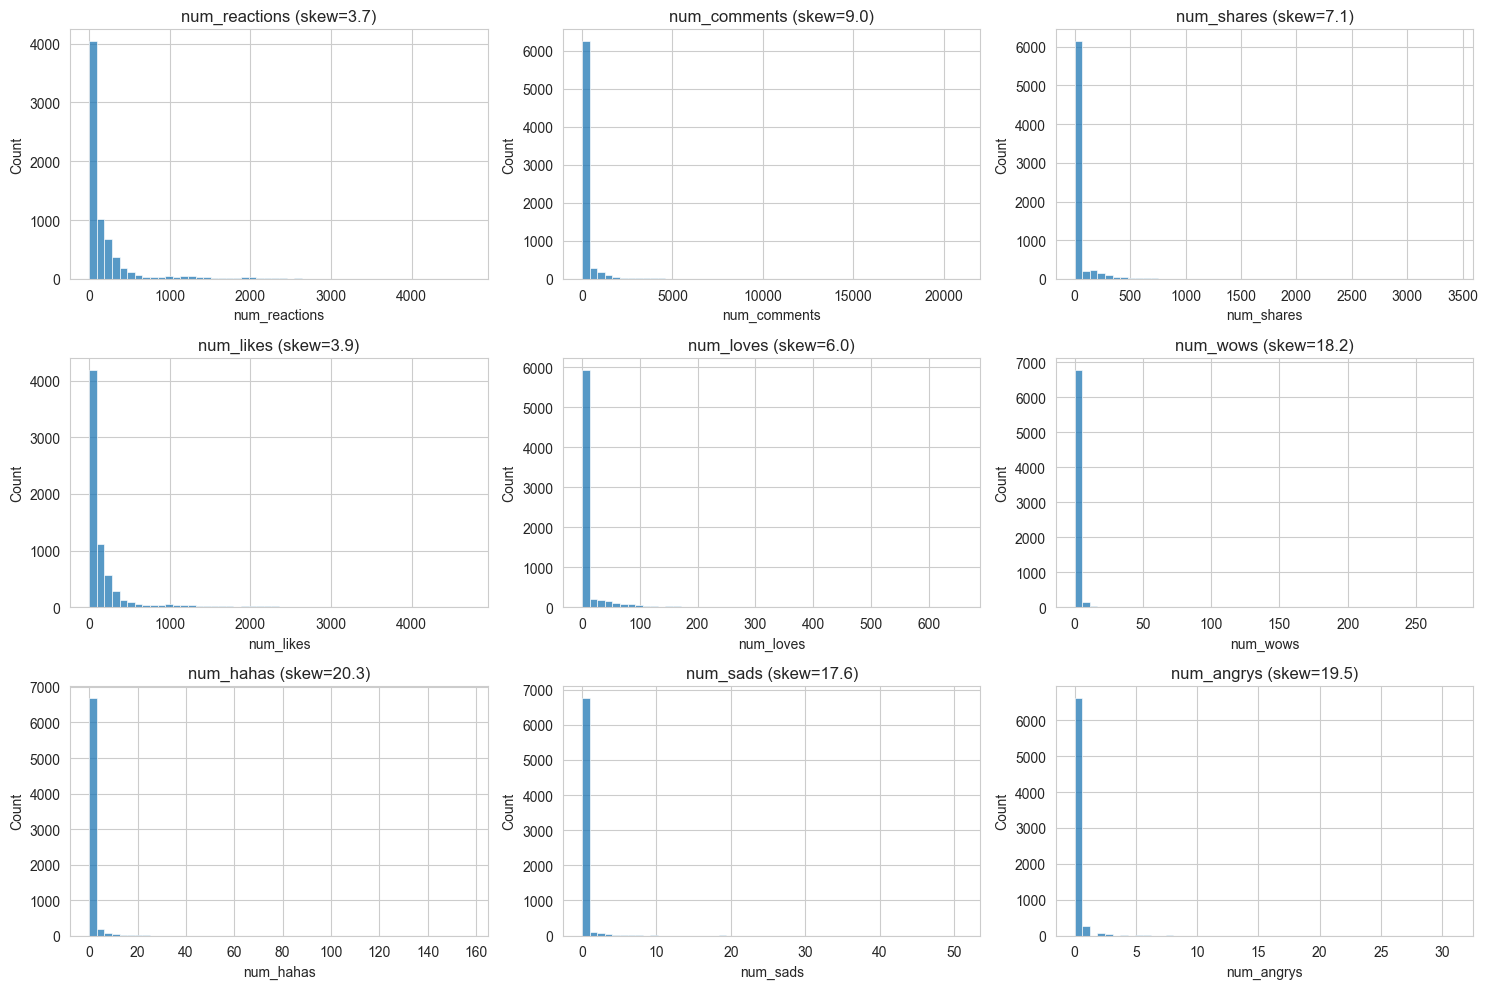

               skewness  proporsi_nol    max  median
num_reactions     3.738         0.017   4710    59.5
num_comments      9.029         0.301  20990     4.0
num_shares        7.099         0.555   3424     0.0
num_likes         3.919         0.018   4710    58.0
num_loves         6.005         0.600    657     0.0
num_wows         18.247         0.753    278     0.0
num_hahas        20.306         0.839    157     0.0
num_sads         17.579         0.914     51     0.0
num_angrys       19.507         0.940     31     0.0


In [40]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
count_cols = ['num_reactions', 'num_comments', 'num_shares', 'num_likes',
              'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), count_cols):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(f'{col} (skew={df[col].skew():.1f})')
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    'skewness': df[count_cols].skew(),
    'proporsi_nol': (df[count_cols] == 0).mean(),
    'max': df[count_cols].max(),
    'median': df[count_cols].median(),
}).round(3)
print((summary))

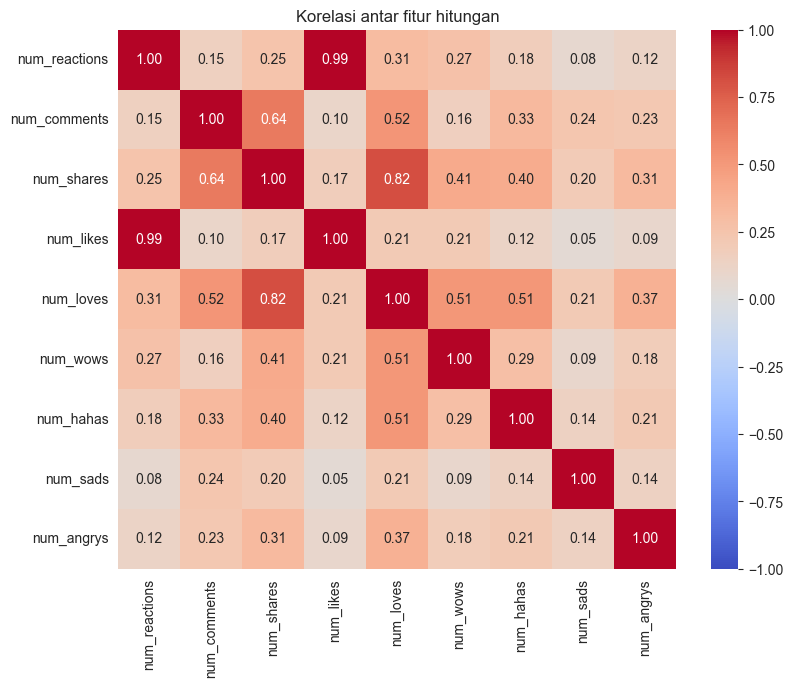

Proporsi baris dengan num_reactions = likes + emoji: 0.9987


In [41]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(9, 7))
sns.heatmap(df[count_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar fitur hitungan')
plt.show()

# Cek apakah num_reactions = likes + semua reaksi emoji
emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
cek = df['num_reactions'] == df['num_likes'] + df[emoji_cols].sum(axis=1)
print(f'Proporsi baris dengan num_reactions = likes + emoji: {cek.mean():.4f}')

      jumlah_posting  proporsi_emoji
year                                
2012             589           0.000
2013             500           0.000
2014             233           0.000
2015             337           0.000
2016             588           0.680
2017            2253           0.542
2018            2550           0.578


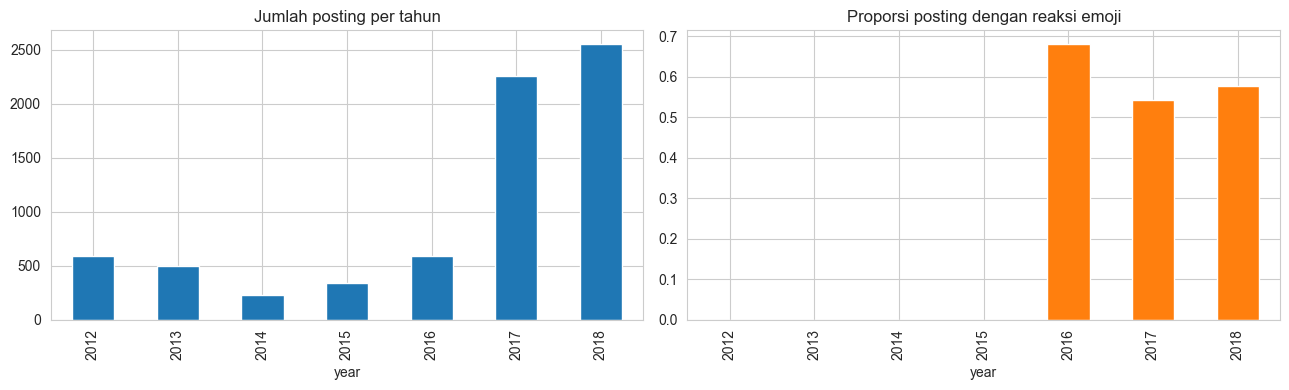

In [42]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'])
df['year'] = df['status_published'].dt.year
df['has_emoji'] = df[emoji_cols].sum(axis=1) > 0

per_tahun = df.groupby('year').agg(jumlah_posting=('status_id', 'count'),
                                   proporsi_emoji=('has_emoji', 'mean'))
print((per_tahun.round(3)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_tahun['jumlah_posting'].plot(kind='bar', ax=axes[0], title='Jumlah posting per tahun')
per_tahun['proporsi_emoji'].plot(kind='bar', ax=axes[1], color='tab:orange',
                                 title='Proporsi posting dengan reaksi emoji')
plt.tight_layout()
plt.show()

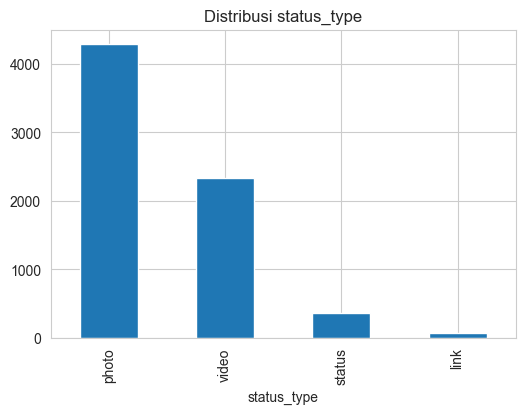

             num_likes  num_comments  num_shares
status_type                                     
link              48.0           1.0         0.0
photo             34.0           2.0         0.0
status           117.0          10.0         0.0
video            117.0          39.0        12.0


In [43]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
fig, ax = plt.subplots(figsize=(6, 4))
df['status_type'].value_counts().plot(kind='bar', ax=ax, title='Distribusi status_type')
plt.show()

print((df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median()))

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [44]:
# Engagement (median) per tahun dan per status_type
print((df.groupby('year')[['num_likes', 'num_comments', 'num_shares']].median()))

      num_likes  num_comments  num_shares
year                                     
2012       19.0           5.0         0.0
2013       55.0           3.0         0.0
2014      437.0          10.0         1.0
2015     1566.0          12.0         1.0
2016      139.0           6.0         0.0
2017       41.0           3.0         0.0
2018       54.5           2.5         1.0


In [45]:
# Komposisi status_type per tahun (%)
print(((pd.crosstab(df['year'], df['status_type'], normalize='index') * 100).round(1)))

status_type  link  photo  status  video
year                                   
2012          0.0  100.0     0.0    0.0
2013          0.0   80.8     0.4   18.8
2014          0.4   10.7     0.0   88.8
2015          4.2   59.9    23.4   12.5
2016          2.4   68.5     8.7   20.4
2017          0.8   56.3     5.4   37.5
2018          0.6   54.7     4.4   40.3


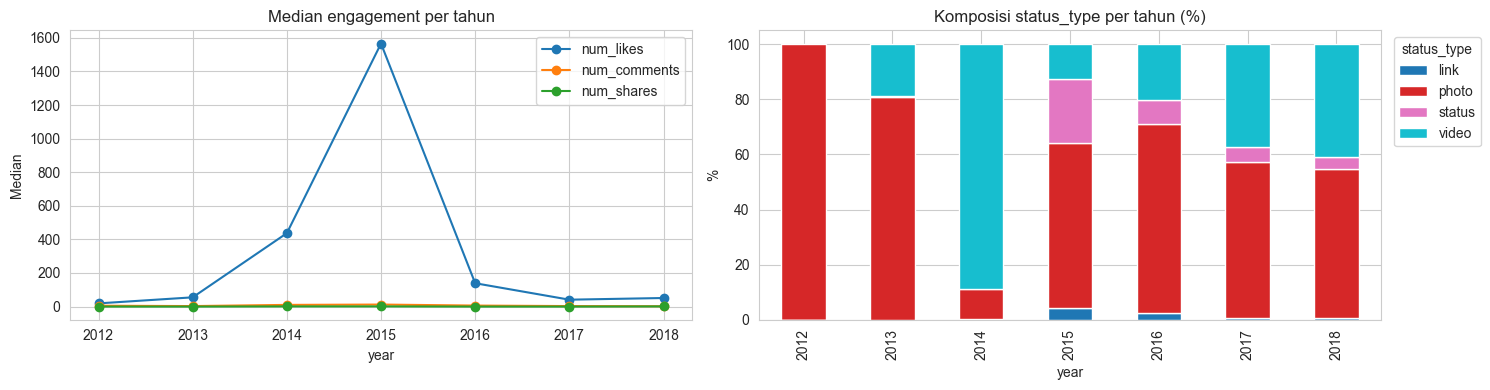

In [68]:
eng_cols = ['num_likes', 'num_comments', 'num_shares']

# Tren engagement dan komposisi status_type per tahun
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df.groupby('year')[eng_cols].median().plot(marker='o', ax=axes[0])
axes[0].set_title('Median engagement per tahun')
axes[0].set_ylabel('Median')

ct_year = pd.crosstab(df['year'], df['status_type'], normalize='index') * 100
ct_year.plot(kind='bar', stacked=True, ax=axes[1], colormap='tab10')
axes[1].set_title('Komposisi status_type per tahun (%)')
axes[1].set_ylabel('%')
axes[1].legend(title='status_type', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

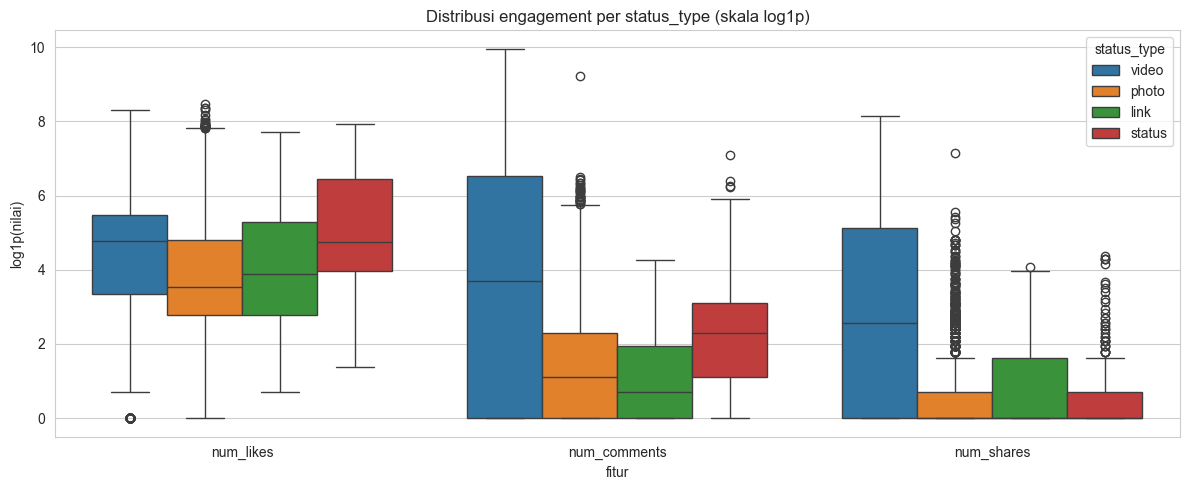

In [69]:
# Distribusi engagement per status_type (skala log agar terbaca)
eng_long = (np.log1p(df[eng_cols])
            .assign(status_type=df['status_type'])
            .melt(id_vars='status_type', var_name='fitur', value_name='log1p(nilai)'))
plt.figure(figsize=(12, 5))
sns.boxplot(data=eng_long, x='fitur', y='log1p(nilai)', hue='status_type')
plt.title('Distribusi engagement per status_type (skala log1p)')
plt.tight_layout()
plt.show()

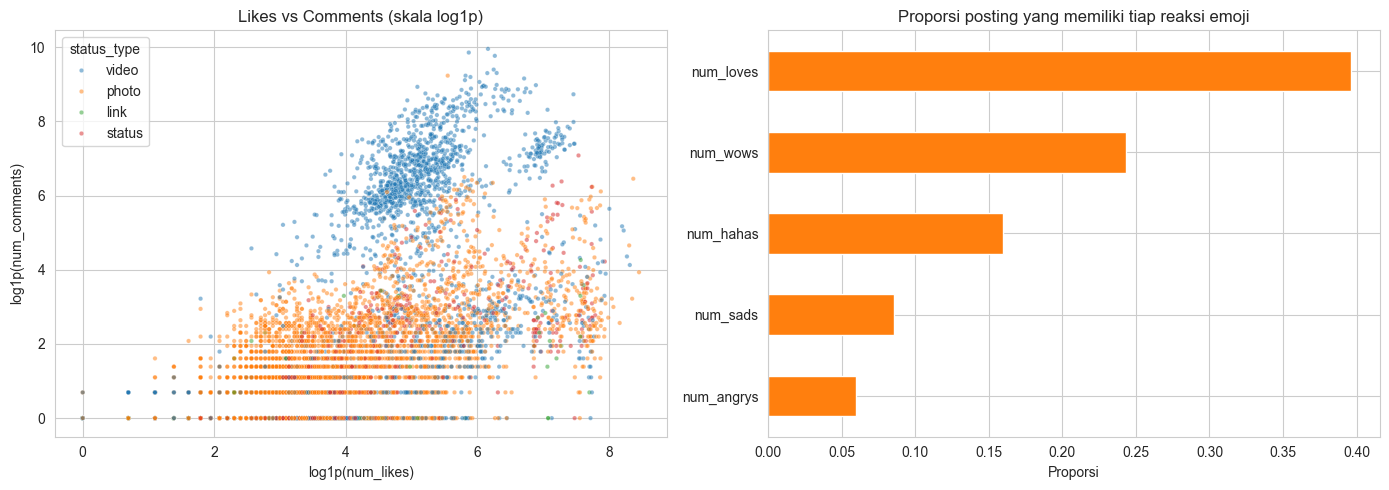

In [70]:
# Hubungan likes vs comments dan seberapa jarang tiap reaksi emoji muncul
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=np.log1p(df['num_likes']), y=np.log1p(df['num_comments']),
                hue=df['status_type'], s=10, alpha=0.5, ax=axes[0])
axes[0].set_xlabel('log1p(num_likes)')
axes[0].set_ylabel('log1p(num_comments)')
axes[0].set_title('Likes vs Comments (skala log1p)')

(df[emoji_cols] > 0).mean().sort_values().plot(kind='barh', ax=axes[1], color='tab:orange')
axes[1].set_title('Proporsi posting yang memiliki tiap reaksi emoji')
axes[1].set_xlabel('Proporsi')
plt.tight_layout()
plt.show()

# 2. Preprocessing

In [46]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
empty_cols = df.columns[df.isna().all()].tolist()
df = df.drop(columns=empty_cols)
print('Kolom kosong yang dihapus:', empty_cols)

n_before = len(df)
df = df[~df.drop(columns='status_id').duplicated()].reset_index(drop=True)
print(f'Duplikat dihapus: {n_before - len(df)} baris -> sisa {len(df)} baris')

print('Missing value tersisa:', df.isna().sum().sum())

# Outlier: hitung jumlah titik di atas Q3 + 3*IQR untuk tiap fitur utama
for col in ['num_likes', 'num_comments', 'num_shares']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    n_out = (df[col] > q3 + 3 * (q3 - q1)).sum()
    print(f'{col}: {n_out} outlier ekstrem (> Q3 + 3*IQR), max = {df[col].max()}')

Kolom kosong yang dihapus: ['Column1', 'Column2', 'Column3', 'Column4']
Duplikat dihapus: 54 baris -> sisa 6996 baris
Missing value tersisa: 0
num_likes: 540 outlier ekstrem (> Q3 + 3*IQR), max = 4710
num_comments: 1245 outlier ekstrem (> Q3 + 3*IQR), max = 20990
num_shares: 1237 outlier ekstrem (> Q3 + 3*IQR), max = 3424


In [47]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
meta = df[['status_type', 'status_published', 'year']].copy()

# Gabungkan reaksi emoji yang sparse menjadi satu fitur
df['num_emoji'] = df[emoji_cols].sum(axis=1)

features = ['num_likes', 'num_comments', 'num_shares', 'num_emoji']
X_df = df[features].copy()
print('Fitur clustering:', features)
display(X_df.describe().T)

Fitur clustering: ['num_likes', 'num_comments', 'num_shares', 'num_emoji']


,count,mean,std,min,25%,50%,75%,max
num_likes,6996.0,210.036735,439.623067,0.0,17.0,57.0,182.00,4710.0
num_comments,6996.0,225.648799,892.922206,0.0,0.0,4.0,22.25,20990.0
num_shares,6996.0,40.275872,132.072584,0.0,0.0,0.0,4.00,3424.0
num_emoji,6996.0,15.051601,47.953856,0.0,0.0,0.0,5.00,886.0


**Fitur yang dipilih untuk clustering:**
`num_likes`, `num_comments`, `num_shares`, `num_emoji`

a. `num_likes` mewakili engagement pasif, yaitu respons paling ringan dan paling umum. Hampir semua posting punya like (hanya ±1,8% bernilai nol), sehingga fitur ini menjadi dasar untuk membedakan posting yang ramai dan yang sepi.

b. `num_comments` mewakili engagement aktif. Audiens perlu usaha lebih untuk berkomentar, dan pada konteks live selling komentar sering dipakai untuk bertanya atau memesan. Dari EDA, median komentar posting video (39) jauh di atas photo (2), jadi fitur ini kuat untuk membedakan tipe posting.

c. `num_shares` mewakili jangkauan atau viralitas, yaitu seberapa jauh posting disebarkan ke luar pengikut penjual. Posting bisa punya banyak like tetapi tidak pernah di-share, sehingga informasinya berbeda dari like.

d. `num_emoji` (gabungan `num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`) mewakili respons emosional, yaitu seberapa ekspresif audiens terhadap posting.

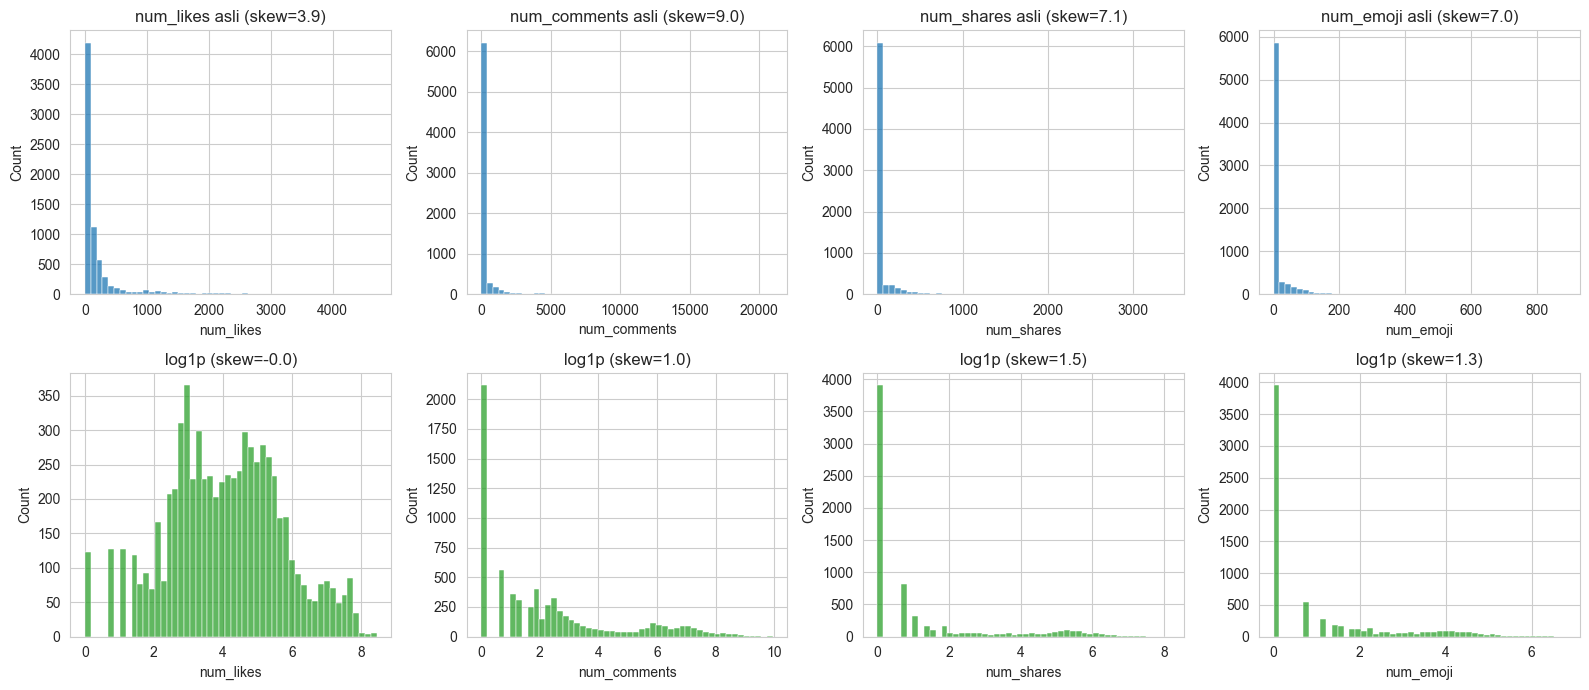

In [48]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X_df)

fig, axes = plt.subplots(2, len(features), figsize=(16, 7))
for i, col in enumerate(features):
    sns.histplot(X_df[col], bins=50, ax=axes[0, i])
    axes[0, i].set_title(f'{col} asli (skew={X_df[col].skew():.1f})')
    sns.histplot(X_log[col], bins=50, ax=axes[1, i], color='tab:green')
    axes[1, i].set_title(f'log1p (skew={X_log[col].skew():.1f})')
plt.tight_layout()
plt.show()

In [49]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
X_raw = X_df.values
X_raw_scaled = StandardScaler().fit_transform(X_df)
X_log_scaled = StandardScaler().fit_transform(X_log)

print('Varians tiap fitur pada X_raw:')
print(pd.Series(X_raw.var(axis=0), index=features).round(1))

Varians tiap fitur pada X_raw:
num_likes       193240.8
num_comments    797196.1
num_shares       17440.7
num_emoji         2299.2
dtype: float64


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [50]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
K_DEMO = 3
versi = {'X_raw': X_raw, 'X_raw_scaled': X_raw_scaled, 'X_log_scaled': X_log_scaled}
labels_versi = {}
for nama, X in versi.items():
    km = KMeans(n_clusters=K_DEMO, random_state=RANDOM_STATE, n_init=10)
    labels_versi[nama] = km.fit_predict(X)

In [51]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
hasil = []
for nama, lab in labels_versi.items():
    hasil.append({
        'versi data': nama,
        'ukuran cluster': sorted(np.bincount(lab).tolist(), reverse=True),
        'silhouette (ruang asli versi tsb)': round(silhouette_score(versi[nama], lab), 3),
        'silhouette (di X_log_scaled)': round(silhouette_score(X_log_scaled, lab), 3),
    })
display(pd.DataFrame(hasil))

var_raw = pd.Series(X_raw.var(axis=0), index=features)
print('Kontribusi varians tiap fitur pada X_raw (%):')
print((var_raw / var_raw.sum() * 100).round(1))

,versi data,ukuran cluster,silhouette (ruang asli versi tsb),silhouette (di X_log_scaled)
0,X_raw,"[6392, 467, 137]",0.789,0.273
1,X_raw_scaled,"[6277, 373, 346]",0.780,0.253
2,X_log_scaled,"[3607, 2258, 1131]",0.464,0.464


Kontribusi varians tiap fitur pada X_raw (%):
num_likes       19.1
num_comments    78.9
num_shares       1.7
num_emoji        0.2
dtype: float64


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [52]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
K_RANGE = range(2, 11)
inertia = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_log_scaled)
    inertia.append(km.inertia_)

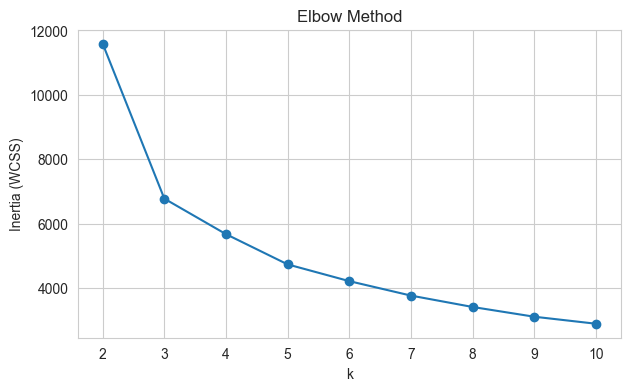

Elbow menurut KneeLocator: k = 4


In [53]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(7, 4))
plt.plot(list(K_RANGE), inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method')
plt.show()

try:
    from kneed import KneeLocator
    kl = KneeLocator(list(K_RANGE), inertia, curve='convex', direction='decreasing')
    print('Elbow menurut KneeLocator: k =', kl.elbow)
except ImportError:
    print(" ")

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [54]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = {}
for k in K_RANGE:
    lab = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_log_scaled)
    sil_scores[k] = silhouette_score(X_log_scaled, lab)
print({k: round(v, 3) for k, v in sil_scores.items()})

{2: 0.59, 3: 0.464, 4: 0.337, 5: 0.359, 6: 0.347, 7: 0.337, 8: 0.315, 9: 0.329, 10: 0.316}


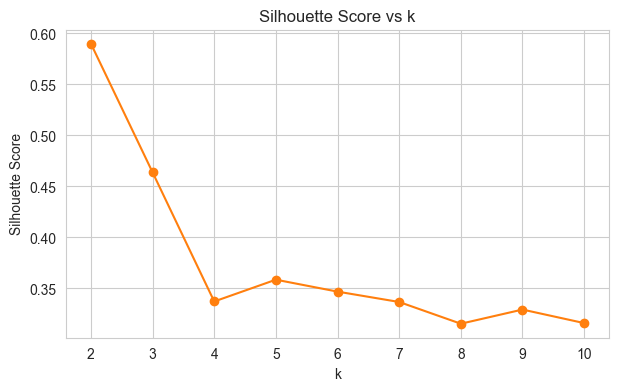

In [55]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(7, 4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), 'o-', color='tab:orange')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs k')
plt.show()

**Pilihan k untuk K-Means:** k = 3.

Penurunan inertia terbesar terjadi dari k = 2 ke k = 3 (11.587 → 6.780) setelah itu penurunannya melandai (k = 4: 5.678). KneeLocator mendeteksi elbow di k = 4, tetapi Silhouette k = 4 turun tajam menjadi 0,337. Silhouette k = 3 masih cukup tinggi (0,464) dan cluster yang dihasilkan mudah ditafsirkan (engagement rendah, sedang, dan tinggi)

## 3.4 Model K-Means Final

In [56]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
K_FINAL = 3
kmeans = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
labels_km = kmeans.fit_predict(X_log_scaled)
print('Ukuran cluster K-Means:', np.bincount(labels_km))

Ukuran cluster K-Means: [1131 2258 3607]


In [57]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
def profil_cluster(labels):
    tmp = X_df.copy()
    tmp['cluster'] = labels
    prof = tmp.groupby('cluster')[features].agg(['median', 'mean']).round(1)
    prof[('jumlah', '')] = tmp['cluster'].value_counts().sort_index()
    return prof

display(profil_cluster(labels_km))

num_likes        num_comments         num_shares        num_emoji  \
           median   mean       median    mean     median   mean    median   
cluster                                                                     
0           170.0  304.5        722.0  1335.4      178.0  238.0      57.0   
1           206.0  462.7         11.0    26.9        1.0    4.7       2.0   
2            18.0   22.2          0.0     2.1        0.0    0.5       0.0   

              jumlah  
         mean         
cluster               
0        83.3   1131  
1         4.6   2258  
2         0.2   3607

# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [58]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z = linkage(X_log_scaled, method='ward')

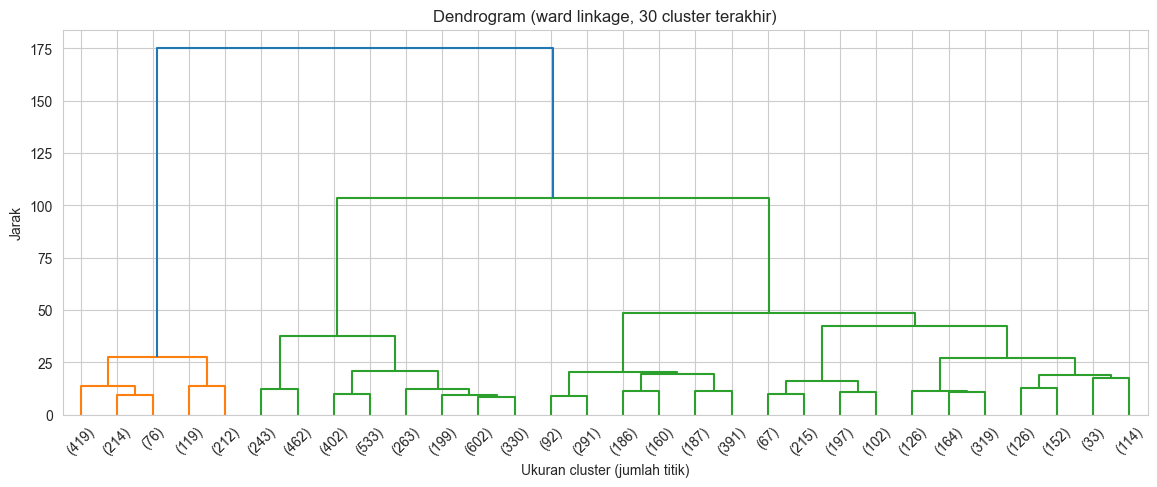

Jarak 5 penggabungan terakhir: [ 37.5  42.3  48.4 103.7 175.1]


In [59]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrogram (ward linkage, 30 cluster terakhir)')
plt.xlabel('Ukuran cluster (jumlah titik)')
plt.ylabel('Jarak')
plt.show()

# Ketinggian 5 merge terakhir, untuk membantu menentukan titik potong
print('Jarak 5 penggabungan terakhir:', Z[-5:, 2].round(1))

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [60]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkages = ['ward', 'complete', 'average', 'single']
labels_link = {}
for lk in linkages:
    labels_link[lk] = AgglomerativeClustering(n_clusters=K_FINAL, linkage=lk).fit_predict(X_log_scaled)

In [61]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
tabel_link = pd.DataFrame([{
    'linkage': lk,
    'silhouette': round(silhouette_score(X_log_scaled, lab), 3),
    'ukuran cluster': sorted(np.bincount(lab).tolist(), reverse=True),
} for lk, lab in labels_link.items()])
display(tabel_link)

,linkage,silhouette,ukuran cluster
0,ward,0.420,"[3034, 2922, 1040]"
1,complete,0.116,"[5775, 761, 460]"
2,average,0.507,"[5764, 1197, 35]"
3,single,0.314,"[6994, 1, 1]"


**Pilihan linkage untuk Hierarchical Clustering:** `ward`. Walaupun `average` memberi Silhouette sedikit lebih tinggi, salah satu clusternya hanya berisi segelintir titik (outlier) sedangkan `single` praktis menaruh hampir semua data di satu cluster. `ward` menghasilkan cluster yang seimbang dan bermakna, serta konsisten dengan dendrogram dan objektif K-Means (meminimalkan varians dalam cluster)

## 4.3 Model Hierarchical Clustering Final

In [62]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
hc = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward')
labels_hc = hc.fit_predict(X_log_scaled)
print('Ukuran cluster HC:', np.bincount(labels_hc))

Ukuran cluster HC: [2922 1040 3034]


In [63]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
display(profil_cluster(labels_hc))

num_likes        num_comments         num_shares        num_emoji  \
           median   mean       median    mean     median   mean    median   
cluster                                                                     
0           150.0  386.8          9.0    29.4        1.0    5.3       1.0   
1           168.0  277.5        815.5  1430.2      193.5  255.4      60.5   
2            14.0   16.7          0.0     1.8        0.0    0.2       0.0   

              jumlah  
         mean         
cluster               
0         4.5   2922  
1        88.2   1040  
2         0.1   3034

# 5. Evaluasi Model

In [64]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
eval_df = pd.DataFrame([
    {'model': nama,
     'Silhouette': silhouette_score(X_log_scaled, lab),
     'Davies-Bouldin': davies_bouldin_score(X_log_scaled, lab),
     'Calinski-Harabasz': calinski_harabasz_score(X_log_scaled, lab)}
    for nama, lab in [('K-Means', labels_km), ('Hierarchical (ward)', labels_hc)]
]).set_index('model').round(3)
display(eval_df)

print('Kesepakatan label (Adjusted Rand Index):',
      round(adjusted_rand_score(labels_km, labels_hc), 3))

,Silhouette,Davies-Bouldin,Calinski-Harabasz
model,,,
K-Means,0.464,0.830,10935.461
Hierarchical (ward),0.420,0.833,9959.188


Kesepakatan label (Adjusted Rand Index): 0.707


Varians dijelaskan: PC1 = 75.9%, PC2 = 16.0%, total = 91.8%


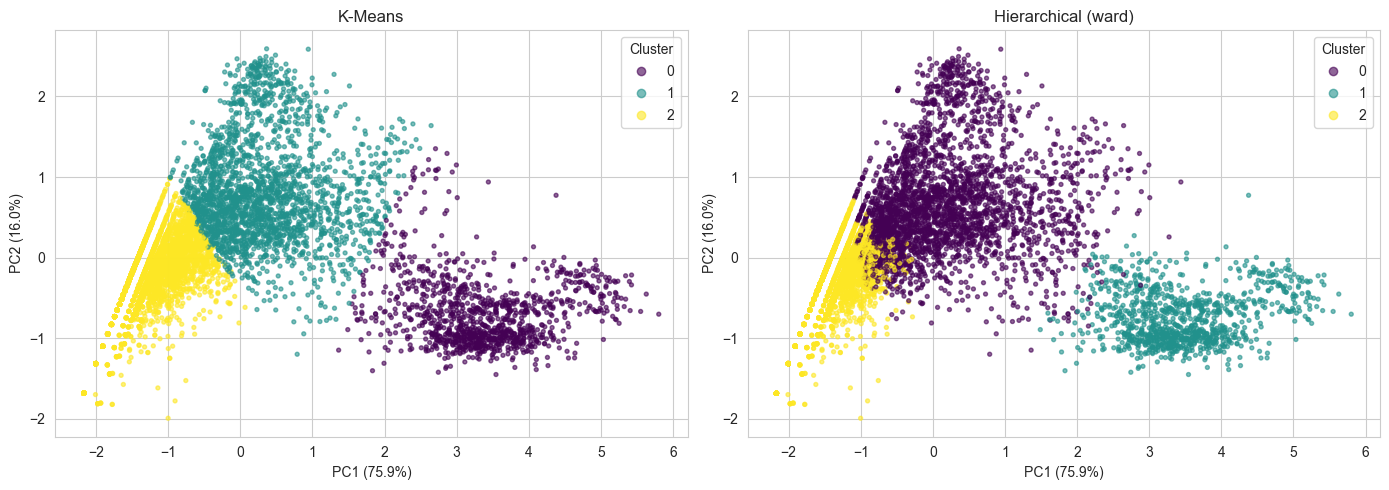

In [65]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_log_scaled)
ev = pca.explained_variance_ratio_
print(f'Varians dijelaskan: PC1 = {ev[0]:.1%}, PC2 = {ev[1]:.1%}, total = {ev.sum():.1%}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (nama, lab) in zip(axes, [('K-Means', labels_km), ('Hierarchical (ward)', labels_hc)]):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap='viridis', s=8, alpha=0.6)
    ax.set_title(nama)
    ax.set_xlabel(f'PC1 ({ev[0]:.1%})')
    ax.set_ylabel(f'PC2 ({ev[1]:.1%})')
    ax.legend(*sc.legend_elements(), title='Cluster')
plt.tight_layout()
plt.show()

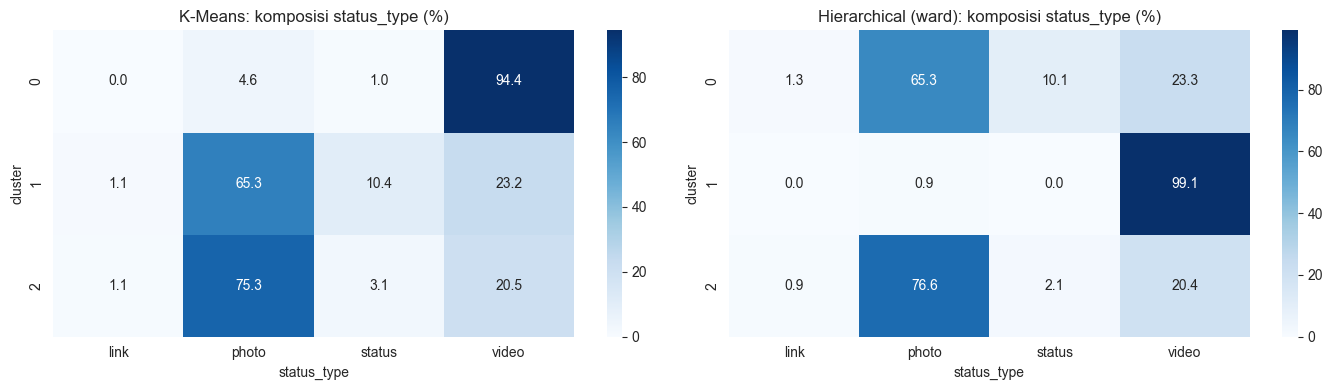

In [66]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (nama, lab) in zip(axes, [('K-Means', labels_km), ('Hierarchical (ward)', labels_hc)]):
    ct = pd.crosstab(lab, meta['status_type'], normalize='index') * 100
    sns.heatmap(ct, annot=True, fmt='.1f', cmap='Blues', ax=ax)
    ax.set_title(f'{nama}: komposisi status_type (%)')
    ax.set_ylabel('cluster')
plt.tight_layout()
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

**1. Pengaruh transformasi log dan feature scaling (bagian 3.1)**

| Versi data | Ukuran cluster | Silhouette (di X_log_scaled) |
|---|---|---|
| X_raw | 6392 / 467 / 137 | 0,273 |
| X_raw_scaled | 6277 / 373 / 346 | 0,253 |
| X_log_scaled | 3607 / 2258 / 1131 | **0,464** |

Pada `X_raw`, `num_comments` menyumbang ±79% total varians dan `num_emoji` hanya 0,2%, sehingga K-Means praktis hanya mengelompokkan berdasarkan jumlah komentar. Hasilnya satu cluster raksasa (>90% data) dan dua cluster kecil berisi posting viral. Scaling saja tidak cukup: setiap fitur memang punya varians sama, tetapi distribusinya tetap sangat miring sehingga outlier ekstrem (misalnya komentar hingga 20.990) masih menarik centroid dan membentuk cluster kecil sendiri. Silhouette di ruang aslinya terlihat tinggi (±0,78) justru karena hampir semua titik ada di satu cluster padat, bukan karena clusternya bermakna. Setelah log1p + scaling, distribusi menjadi lebih simetris, jarak antar posting lebih mencerminkan perbedaan relatif (10 vs 100 like sama pentingnya dengan 100 vs 1.000), dan cluster menjadi seimbang dengan Silhouette tertinggi. Kesimpulannya, pada algoritma berbasis jarak Euclidean, log mengatasi skewness/outlier dan scaling menyamakan kontribusi tiap fitur; keduanya dibutuhkan.

**2. Penanganan kolom redundan dan sparse**

`num_reactions` dibuang karena 99,87% barisnya persis sama dengan `num_likes` + total emoji (korelasi dengan `num_likes` hampir 1), sehingga akan menggandakan bobot like. Kelima reaksi emoji digabung menjadi `num_emoji` karena masing-masing 60–94% bernilai nol. Selain itu, reaksi emoji baru ada sejak 2016 sehingga semua posting 2012–2015 bernilai nol; jika dipakai sebagai lima fitur terpisah, faktor "tahun posting" ini akan terlalu mendominasi jarak. Fitur akhir: `num_likes`, `num_comments`, `num_shares`, `num_emoji`.

**3. Jumlah cluster optimal**

Elbow (KneeLocator) memberi k = 4, sedangkan Silhouette memberi k = 2, sehingga keduanya tidak sepakat. Dipilih k = 3: siku visual paling jelas ada di k = 3 (penurunan inertia terbesar terakhir), Silhouette k = 3 (0,464) jauh lebih baik dibanding k = 4 (0,337), dan k = 3 lebih informatif daripada k = 2. Dendrogram ward juga mendukung: lompatan jarak dari 48,4 ke 103,7 menunjukkan potongan alami di 3 cluster.

**4. Perbandingan linkage (k = 3)**

| Linkage | Silhouette | Ukuran cluster |
|---|---|---|
| ward | 0,420 | 3034 / 2922 / 1040 |
| complete | 0,116 | 5775 / 761 / 460 |
| average | 0,507 | 5764 / 1197 / 35 |
| single | 0,314 | 6994 / 1 / 1 |

Silhouette `average` paling tinggi, tetapi satu clusternya hanya 35 titik (kumpulan outlier), jadi angkanya "menipu". `single` mengalami chaining effect: karena jarak antar-cluster diukur dari pasangan titik terdekat, titik-titik saling menyambung menjadi satu cluster raksasa (6.994 titik) dan dua cluster lain hanya berisi 1 outlier. `complete` menghasilkan pemisahan buruk (Silhouette 0,116). `ward` dipilih karena clusternya seimbang dan bermakna, dengan meminimalkan kenaikan varians di setiap penggabungan.

**5. K-Means vs Hierarchical Clustering**

| Model | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabasz ↑ |
|---|---|---|---|
| K-Means | 0,464 | 0,830 | 10.935 |
| Hierarchical (ward) | 0,420 | 0,833 | 9.959 |

K-Means sedikit lebih unggul di ketiga metrik, tetapi selisihnya kecil. Adjusted Rand Index antara keduanya 0,707 dan visualisasi PCA (2 komponen menjelaskan 91,8% varians) menunjukkan pembagian yang sangat mirip: struktur data berupa satu "gradien" engagement di sepanjang PC1. Hal ini wajar karena ward dan K-Means sama-sama meminimalkan varians dalam cluster. Perbedaan utamanya ada di perbatasan cluster rendah–sedang: K-Means mengoptimalkan ulang posisi centroid secara iteratif, sedangkan ward bersifat greedy (penggabungan yang sudah terjadi tidak bisa dibatalkan), sehingga K-Means mendapat skor sedikit lebih baik.

**6. Karakteristik cluster (K-Means; HC sangat mirip)**

| Cluster | n | Median likes / comments / shares / emoji | status_type dominan | Julukan |
|---|---|---|---|---|
| 0 | 1131 | 170 / 722 / 178 / 57 | video 94% | "Live Video Viral": komentar dan share sangat tinggi, kemungkinan besar sesi live selling |
| 1 | 2258 | 206 / 11 / 1 / 2 | photo 65%, video 23%, status 10% | "Disukai tapi Pasif": like banyak, interaksi lain sedikit |
| 2 | 3607 | 18 / 0 / 0 / 0 | photo 75% | "Posting Sepi": engagement minim, mayoritas foto katalog |

Cluster 0 seluruhnya berasal dari tahun ≥ 2016, konsisten dengan populernya fitur Facebook Live sejak saat itu. Cluster HC berpadanan dengan cluster K-Means (HC 1 ≈ KM 0 dengan 99% video, HC 0 ≈ KM 1, HC 2 ≈ KM 2).

**7. Kelebihan dan kekurangan**

- **K-Means**: cepat dan hemat memori (≈ O(n·k·iterasi)), mudah diskalakan ke data besar. Kekurangannya, k harus ditentukan di awal, sensitif terhadap inisialisasi dan outlier, serta mengasumsikan cluster berbentuk bulat dengan ukuran mirip.
- **Hierarchical (Agglomerative)**: tidak perlu menentukan k di awal (cukup potong dendrogram), dendrogram memberi gambaran struktur data di berbagai tingkat, dan deterministik. Kekurangannya, kebutuhan memori O(n²) dan waktu ≥ O(n²) sehingga berat untuk data besar, keputusan merge tidak bisa dibatalkan, dan hasil sangat bergantung pada pilihan linkage (seperti terlihat pada `single`).

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**

Data engagement Facebook memiliki distribusi yang sangat miring dan banyak outlier, sehingga transformasi Log1p dan StandardScaler berperan penting dalam meningkatkan kualitas clustering. K-Means dengan k = 3 sedikit lebih unggul dibandingkan Hierarchical Clustering metode Ward, tetapi keduanya menghasilkan pola cluster serupa, yaitu Live Video Viral, Disukai tapi Pasif, dan Posting Sepi. Hasil ini menunjukkan bahwa konten live video menjadi pendorong utama komentar dan share.

**Saran**

Penelitian selanjutnya disarankan menguji k = 4 secara lebih mendalam untuk mengidentifikasi kemungkinan sub-pola dalam cluster “Disukai tapi Pasif”. Selain itu, penambahan fitur rasio engagement, seperti komentar per like dan share per like, dapat membantu membedakan pola respons pada posting yang sama-sama populer. Normalisasi engagement berdasarkan ukuran akun penjual juga perlu dipertimbangkan agar hasil clustering tidak hanya dipengaruhi jumlah pengikut. Selanjutnya, stabilitas cluster perlu diuji menggunakan beberapa subsampel data, sementara posting viral dapat dianalisis secara terpisah berdasarkan jenis konten, waktu publikasi, dan penjual untuk memperoleh insight bisnis yang lebih mendalam.